# Classificação e avaliação — Online Shoppers Purchasing Intention

Este notebook treina e avalia os quatro algoritmos usando os pipelines montados em `02_preprocessamento/`:

1. Divisão da base em treino (80%) e teste (20%), estratificada
2. Busca em grade com validação cruzada estratificada (10 folds) no treino para testar as parametrizações de cada algoritmo
3. Escolha das métricas de avaliação
4. Escolha da melhor parametrização de cada algoritmo
5. Avaliação final no teste: métricas, matrizes de confusão e tabela comparativa

Os gráficos são salvos em `figuras/` e as tabelas em `tabelas/` (nesta mesma pasta).

## Configuração

In [1]:
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (accuracy_score, average_precision_score, balanced_accuracy_score,
                             confusion_matrix, f1_score, make_scorer, matthews_corrcoef,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate, train_test_split

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").exists())
PASTA = RAIZ / "03_classificacao"
ARQUIVO_DADOS = RAIZ / "data" / "processed" / "online_shoppers_limpo.csv"
DIR_PIPELINES = RAIZ / "02_preprocessamento" / "pipelines"
DIR_FIG = PASTA / "figuras"
DIR_TAB = PASTA / "tabelas"
DIR_FIG.mkdir(parents=True, exist_ok=True)
DIR_TAB.mkdir(parents=True, exist_ok=True)

SEMENTE = 42
N_FOLDS = 10
TAMANHO_TESTE = 0.20
CLASSE = "Revenue"

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:.4f}".format)

In [2]:
# Estilo dos gráficos (mesmo da análise exploratória)
COR = {
    "texto": "#0b0b0b",
    "texto2": "#52514e",
    "mudo": "#898781",
    "grade": "#e1e0d9",
    "eixo": "#c3c2b7",
    "fundo": "#fcfcfb",
}
# Uma cor fixa por algoritmo, em todos os gráficos
COR_ALGORITMO = {
    "KNN": "#2a78d6",
    "Random Forest": "#eb6834",
    "Gradient Boosting": "#1baf7a",
    "MLP": "#eda100",
}
MAPA_SEQUENCIAL = LinearSegmentedColormap.from_list("azul", ["#f0efec", "#86b6ef", "#1c5cab"])

plt.rcParams.update({
    "figure.facecolor": COR["fundo"],
    "axes.facecolor": COR["fundo"],
    "savefig.facecolor": COR["fundo"],
    "axes.edgecolor": COR["eixo"],
    "axes.labelcolor": COR["texto2"],
    "axes.titlecolor": COR["texto"],
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": COR["grade"],
    "grid.linewidth": 0.6,
    "axes.axisbelow": True,
    "xtick.color": COR["texto2"],
    "ytick.color": COR["texto2"],
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.frameon": False,
    "legend.fontsize": 9,
    "font.size": 9,
    "figure.dpi": 100,
    "savefig.dpi": 200,
    "savefig.bbox": "tight",
})


def salvar_tabela(tabela, nome, index=True):
    tabela.to_csv(DIR_TAB / f"{nome}.csv", index=index, float_format="%.4f")


def salvar_figura(fig, nome):
    """Salva o PNG em figuras/ e exibe o gráfico no notebook."""
    fig.savefig(DIR_FIG / f"{nome}.png")
    plt.show()


def legenda_algoritmos(fig, algoritmos=COR_ALGORITMO, **kwargs):
    alcas = [Line2D([], [], marker="o", linestyle="", markersize=8, color=COR_ALGORITMO[a]) for a in algoritmos]
    fig.legend(alcas, list(algoritmos), ncol=len(algoritmos), loc="upper center", **kwargs)

## 1. Divisão em treino e teste

A base limpa (após as etapas comuns do pré-processamento) é dividida **uma única vez** em 80% de treino e 20% de
teste, de forma **estratificada**: as duas partes mantêm a mesma proporção de compradores (cerca de 15,6%).

- O **treino** é usado na validação cruzada para comparar as parametrizações de cada algoritmo.
- O **teste** fica guardado até o final. Só é usado uma vez, para avaliar a melhor parametrização de cada
  algoritmo. Assim, a escolha dos hiperparâmetros não é influenciada pelos dados em que o resultado final é medido.

In [3]:
df = pd.read_csv(ARQUIVO_DADOS)
X = df.drop(columns=CLASSE)
y = df[CLASSE]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=TAMANHO_TESTE, stratify=y, random_state=SEMENTE
)

divisao = pd.DataFrame({
    "instancias": [len(y), len(y_treino), len(y_teste)],
    "nao_comprou": [int((y == 0).sum()), int((y_treino == 0).sum()), int((y_teste == 0).sum())],
    "comprou": [int(y.sum()), int(y_treino.sum()), int(y_teste.sum())],
}, index=["base limpa", "treino (80%)", "teste (20%)"])
divisao["pct_comprou"] = 100 * divisao["comprou"] / divisao["instancias"]
salvar_tabela(divisao, "01_divisao_treino_teste")
divisao.round(2)

,instancias,nao_comprou,comprou,pct_comprou
base limpa,12205,10297,1908,15.6300
treino (80%),9764,8238,1526,15.6300
teste (20%),2441,2059,382,15.6500


## 2. Validação cruzada para testar as parametrizações

No conjunto de treino, cada parametrização é avaliada com **validação cruzada estratificada de 10 folds**
(`StratifiedKFold`, com embaralhamento e semente fixa):

- O treino é dividido em 10 partes com a mesma proporção de compradores. Em cada rodada, 9 partes treinam o modelo
  e 1 parte o avalia. Cada instância é usada para avaliação exatamente uma vez.
- **Os mesmos 10 folds são usados para todos os algoritmos e parametrizações**, então as diferenças entre os
  resultados vêm dos modelos e não de divisões diferentes dos dados.
- Os pipelines são reajustados do zero em cada fold: min-max, z-score, agrupamento de categorias raras e
  sobreamostragem aprendem só com as 9 partes de treino, e a parte de avaliação mantém a proporção real das classes.
- O resultado de cada métrica é a **média dos 10 folds**, acompanhada do **desvio padrão**, que indica o quanto o
  resultado varia conforme os dados usados.

In [4]:
CV = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEMENTE)

ESCORES = {
    "acuracia": "accuracy",
    "acuracia_balanceada": "balanced_accuracy",
    "precisao": make_scorer(precision_score, zero_division=0),
    "revocacao": "recall",
    "f1": make_scorer(f1_score, zero_division=0),
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "mcc": make_scorer(matthews_corrcoef),
}
NOME_METRICA = {
    "acuracia": "Acurácia",
    "acuracia_balanceada": "Acurácia balanceada",
    "precisao": "Precisão",
    "revocacao": "Revocação",
    "f1": "F1",
    "roc_auc": "ROC-AUC",
    "pr_auc": "PR-AUC",
    "mcc": "MCC",
}
METRICAS = list(ESCORES)

## 3. Algoritmos e grades de parâmetros

Cada algoritmo é carregado do seu pipeline (pré-processamento + balanceamento + modelo), e os hiperparâmetros do
modelo são escolhidos por **busca em grade** (`GridSearchCV`). Para cada algoritmo, os principais parâmetros
recebem uma lista de valores, e **todas as combinações** são avaliadas com a validação cruzada da seção 2 (os mesmos
10 folds). Nenhum parâmetro principal fica fixo por escolha prévia: a melhor combinação é a indicada pelos
resultados.

| Algoritmo | Parâmetro | Valores testados | O que controla |
|---|---|---|---|
| KNN | `n_neighbors` (k) | 5, 15, 31, 51, 101 | Quantos vizinhos votam. Com k pequeno, a decisão segue poucos vizinhos e fica sensível a ruído; com k grande, a fronteira de decisão fica mais suave. Valores ímpares evitam empate no voto. |
| | `weights` | uniform, distance | Se todos os k vizinhos têm o mesmo peso no voto ou se os mais próximos pesam mais. |
| | `p` | 1 (Manhattan), 2 (Euclidiana) | Distância usada. A euclidiana eleva as diferenças ao quadrado, então um atributo com diferença grande domina; a Manhattan soma as diferenças absolutas. |
| Random Forest | `n_estimators` | 100, 300 | Número de árvores. Mais árvores deixam a votação mais estável, com custo maior. |
| | `max_features` | sqrt, 0.5 | Quantos atributos são sorteados como candidatos em cada divisão: a raiz quadrada do total ou metade dos atributos. Menos candidatos deixam as árvores mais diferentes entre si. |
| | `max_depth` | None, 10 | Profundidade máxima de cada árvore (None = sem limite). |
| | `min_samples_leaf` | 1, 5 | Mínimo de instâncias em cada folha. Valores maiores impedem folhas que decoram uma única sessão. |
| Gradient Boosting | `learning_rate` | 0.05, 0.1, 0.2 | Quanto cada nova árvore corrige o erro das anteriores. |
| | `max_iter` | 100, 300 | Número de árvores somadas. Taxas menores precisam de mais árvores. |
| | `max_depth` | None, 3, 6 | Profundidade de cada árvore (None = limitada só pelo número de folhas, 31 por padrão). |
| MLP | `hidden_layer_sizes` | (10,), (50,), (100,) | Número de neurônios na camada oculta. |
| | `alpha` | 0.0001, 0.01, 1 | Força da regularização L2, que penaliza pesos grandes e reduz o sobreajuste. |
| | `activation` | relu, tanh | Função de ativação dos neurônios ocultos. |

O que permanece fixo, e por quê:
- `random_state=42` em todos os modelos: torna os resultados reprodutíveis.
- `class_weight="balanced"` (Random Forest e Gradient Boosting) e sobreamostragem (KNN e MLP) fazem parte do
  tratamento do desbalanceamento definido no pré-processamento.
- `max_iter=1000` no MLP é um limite de segurança para o treino, não um parâmetro do modelo: o treino para antes,
  assim que a perda deixa de melhorar.
- Os demais parâmetros usam os valores padrão do scikit-learn (por exemplo, o otimizador `adam` no MLP).

In [5]:
GRADES = {
    "KNN": ("knn.joblib", {
        "n_neighbors": [5, 15, 31, 51, 101],
        "weights": ["uniform", "distance"],
        "p": [1, 2],
    }),
    "Random Forest": ("random_forest.joblib", {
        "n_estimators": [100, 300],
        "max_features": ["sqrt", 0.5],
        "max_depth": [None, 10],
        "min_samples_leaf": [1, 5],
    }),
    "Gradient Boosting": ("gradient_boosting.joblib", {
        "learning_rate": [0.05, 0.1, 0.2],
        "max_iter": [100, 300],
        "max_depth": [None, 3, 6],
    }),
    "MLP": ("mlp.joblib", {
        "hidden_layer_sizes": [(10,), (50,), (100,)],
        "alpha": [0.0001, 0.01, 1.0],
        "activation": ["relu", "tanh"],
    }),
}
FIXOS = {"MLP": {"max_iter": 1000}}


def rotulo(algoritmo, params):
    """Nome legível de uma combinação, na ordem da grade."""
    return ", ".join(f"{p}={params[p]}" for p in GRADES[algoritmo][1])


def montar_pipeline(algoritmo, params):
    arquivo, _ = GRADES[algoritmo]
    todos = FIXOS.get(algoritmo, {}) | params
    return joblib.load(DIR_PIPELINES / arquivo).set_params(**{f"modelo__{k}": v for k, v in todos.items()})


tabela_grades = pd.DataFrame([
    {"algoritmo": alg, "parametro": p, "valores_testados": ", ".join(map(str, valores))}
    for alg, (_, grade) in GRADES.items() for p, valores in grade.items()
])
salvar_tabela(tabela_grades, "02_grades_de_parametros", index=False)

n_combinacoes = {alg: int(np.prod([len(v) for v in grade.values()])) for alg, (_, grade) in GRADES.items()}
print("Combinações por algoritmo:", n_combinacoes)
print(f"Total: {sum(n_combinacoes.values())} combinações x {N_FOLDS} folds = "
      f"{sum(n_combinacoes.values()) * N_FOLDS} treinos")

Combinações por algoritmo: {'KNN': 20, 'Random Forest': 16, 'Gradient Boosting': 18, 'MLP': 18}
Total: 72 combinações x 10 folds = 720 treinos


## 4. Execução da busca em grade

Além das combinações da grade, duas **linhas de base** que não aprendem nada com os atributos são avaliadas nos
mesmos folds. Elas mostram o valor que cada métrica atinge "de graça" e ajudam a escolher as métricas na seção 5:

- **Sempre "não comprou"** (`DummyClassifier(strategy="most_frequent")`): prevê sempre a classe majoritária.
- **Sorteio** (`DummyClassifier(strategy="stratified")`): prevê "comprou" ao acaso em ~15,6% das sessões.

A busca é feita com `refit=False`: aqui só são calculadas as métricas de todas as combinações. A escolha da melhor
fica para a seção 6, depois da escolha das métricas. Esta célula leva cerca de 10 minutos, quase todos no MLP.

In [6]:
# O ConvergenceWarning do MLP é verificado separadamente na seção 7, no ajuste final
warnings.filterwarnings("ignore", category=ConvergenceWarning)

LINHAS_DE_BASE = {
    "sempre 'não comprou'": DummyClassifier(strategy="most_frequent"),
    "sorteio estratificado": DummyClassifier(strategy="stratified", random_state=SEMENTE),
}

linhas = []
for nome, modelo in LINHAS_DE_BASE.items():
    r = cross_validate(modelo, X_treino, y_treino, cv=CV, scoring=ESCORES)
    for fold in range(N_FOLDS):
        linhas.append({"algoritmo": "Linha de base", "configuracao": nome, "fold": fold + 1,
                       "tempo_medio_treino_s": r["fit_time"].mean(),
                       **{m: r[f"test_{m}"][fold] for m in METRICAS}})

PARAMS = {}  # (algoritmo, configuração) -> hiperparâmetros da combinação
for algoritmo, (_, grade) in GRADES.items():
    inicio = time.perf_counter()
    pipeline = montar_pipeline(algoritmo, {})
    if algoritmo == "Random Forest":
        pipeline.set_params(modelo__n_jobs=1)  # a busca já distribui as combinações entre os núcleos
    busca = GridSearchCV(pipeline, {f"modelo__{p}": v for p, v in grade.items()},
                         cv=CV, scoring=ESCORES, refit=False, n_jobs=-1)
    busca.fit(X_treino, y_treino)
    r = busca.cv_results_
    for i, params in enumerate(r["params"]):
        params = {k.removeprefix("modelo__"): v for k, v in params.items()}
        configuracao = rotulo(algoritmo, params)
        PARAMS[(algoritmo, configuracao)] = params
        for fold in range(N_FOLDS):
            linhas.append({"algoritmo": algoritmo, "configuracao": configuracao, "fold": fold + 1,
                           "tempo_medio_treino_s": r["mean_fit_time"][i],
                           **{m: r[f"split{fold}_test_{m}"][i] for m in METRICAS}})
    print(f"{algoritmo:<18} {len(r['params']):>2} combinações em {time.perf_counter() - inicio:4.0f} s | "
          f"F1 médio de {r['mean_test_f1'].min():.3f} a {r['mean_test_f1'].max():.3f}")

resultados_folds = pd.DataFrame(linhas)
salvar_tabela(resultados_folds, "03_validacao_cruzada_por_fold", index=False)

KNN                20 combinações em   30 s | F1 médio de 0.420 a 0.515


Random Forest      16 combinações em   39 s | F1 médio de 0.660 a 0.681


Gradient Boosting  18 combinações em   28 s | F1 médio de 0.650 a 0.668


MLP                18 combinações em  511 s | F1 médio de 0.556 a 0.646


In [7]:
agrupado = resultados_folds.groupby(["algoritmo", "configuracao"], sort=False)
media = agrupado[METRICAS + ["tempo_medio_treino_s"]].mean()
desvio = agrupado[METRICAS].std(ddof=0)
resumo_cv = media.join(desvio.add_suffix("_dp"))
salvar_tabela(resumo_cv, "04_validacao_cruzada_resumo")
modelos_cv = media.drop(index="Linha de base")


def media_mais_desvio(indices, metricas=METRICAS):
    """Tabela no formato "média ± desvio" para exibição."""
    return pd.DataFrame({
        NOME_METRICA[m]: media.loc[indices, m].map("{:.3f}".format) + " ± "
        + desvio.loc[indices, m].map("{:.3f}".format)
        for m in metricas
    }, index=indices)


print(f"{len(modelos_cv)} combinações avaliadas. Resultados completos em tabelas/04_validacao_cruzada_resumo.csv")

72 combinações avaliadas. Resultados completos em tabelas/04_validacao_cruzada_resumo.csv


## 5. Escolha das métricas

A base tem 84,4% de sessões sem compra e 15,6% com compra, e o interesse está na classe minoritária: identificar
quem vai comprar. Com esse desbalanceamento, métricas diferentes contam histórias muito diferentes. As três análises
abaixo usam os resultados da validação cruzada para decidir quais métricas devem guiar as escolhas.

### 5.1 O que as linhas de base atingem sem aprender nada

In [8]:
base = media.loc["Linha de base", METRICAS].rename(columns=NOME_METRICA)
base

,Acurácia,Acurácia balanceada,Precisão,Revocação,F1,ROC-AUC,PR-AUC,MCC
configuracao,,,,,,,,
sempre 'não comprou',0.8437,0.5000,0.0000,0.0000,0.0000,0.5000,0.1563,0.0000
sorteio estratificado,0.7335,0.4980,0.1529,0.1553,0.1541,0.4980,0.1560,-0.0041


O classificador que **nunca prevê uma compra** tem 84,4% de acurácia, um número que parece bom, mas ele não
encontra nenhum comprador. Nas métricas centradas na classe positiva (precisão, revocação, F1) ele tem 0, e o
sorteio fica perto de 0,16. A acurácia, portanto, não serve para julgar os modelos neste problema: qualquer valor
precisa ser comparado com 84,4%, e um modelo pode aumentá-la simplesmente prevendo menos compras.

### 5.2 Qual parametrização cada métrica escolheria

Para cada algoritmo, a tabela mostra a parametrização que seria escolhida se a decisão fosse tomada pela acurácia,
pelo F1, pela PR-AUC ou pela revocação (fração de compradores encontrados), e os valores que cada escolha teria.

In [9]:
escolhas = []
for algoritmo in GRADES:
    bloco = modelos_cv.loc[algoritmo]
    for metrica in ["acuracia", "f1", "pr_auc", "revocacao"]:
        melhor = bloco[metrica].idxmax()
        escolhas.append({"algoritmo": algoritmo, "escolhida_por": NOME_METRICA[metrica],
                         "configuracao": melhor, "acuracia": bloco.loc[melhor, "acuracia"],
                         "f1": bloco.loc[melhor, "f1"], "pr_auc": bloco.loc[melhor, "pr_auc"],
                         "revocacao": bloco.loc[melhor, "revocacao"],
                         "precisao": bloco.loc[melhor, "precisao"]})
escolhas = pd.DataFrame(escolhas).set_index(["algoritmo", "escolhida_por"])
salvar_tabela(escolhas, "05_escolha_por_metrica")
escolhas

configuracao  \
algoritmo         escolhida_por                                                      
KNN               Acurácia                   n_neighbors=51, weights=distance, p=1   
                  F1                         n_neighbors=51, weights=distance, p=1   
                  PR-AUC                    n_neighbors=101, weights=distance, p=1   
                  Revocação                   n_neighbors=51, weights=uniform, p=1   
Random Forest     Acurácia       n_estimators=100, max_features=sqrt, max_depth...   
                  F1             n_estimators=300, max_features=sqrt, max_depth...   
                  PR-AUC         n_estimators=300, max_features=0.5, max_depth=...   
                  Revocação      n_estimators=100, max_features=0.5, max_depth=...   
Gradient Boosting Acurácia         learning_rate=0.2, max_iter=300, max_depth=None   
                  F1              learning_rate=0.05, max_iter=300, max_depth=None   
                  PR-AUC          learning_rate=0.05, max_iter=100, max_depth=None   
                  Revocação          learning_rate=0.05, max_iter=100, max_depth=3   
MLP               Acurácia       hidden_layer_sizes=(100,), alpha=0.0001, activ...   
                  F1             hidden_layer_sizes=(50,), alpha=1.0, activatio...   
                  PR-AUC         hidden_layer_sizes=(100,), alpha=1.0, activati...   
                  Revocação      hidden_layer_sizes=(10,), alpha=1.0, activatio...   

                                 acuracia     f1  pr_auc  revocacao  precisao  
algoritmo         escolhida_por                                                
KNN               Acurácia         0.7790 0.5145  0.5138     0.7491    0.3921  
                  F1               0.7790 0.5145  0.5138     0.7491    0.3921  
                  PR-AUC           0.7707 0.5075  0.5256     0.7556    0.3822  
                  Revocação        0.7570 0.4984  0.4975     0.7720    0.3683  
Random Forest     Acurácia         0.8926 0.6794  0.7315     0.7281    0.6377  
                  F1               0.8923 0.6815  0.7381     0.7373    0.6342  
                  PR-AUC           0.8722 0.6686  0.7493     0.8237    0.5632  
                  Revocação        0.8723 0.6693  0.7451     0.8257    0.5631  
Gradient Boosting Acurácia         0.8950 0.6580  0.7154     0.6474    0.6700  
                  F1               0.8833 0.6685  0.7386     0.7529    0.6016  
                  PR-AUC           0.8718 0.6646  0.7519     0.8126    0.5623  
                  Revocação        0.8590 0.6522  0.7479     0.8454    0.5312  
MLP               Acurácia         0.8643 0.5692  0.5819     0.5734    0.5663  
                  F1               0.8621 0.6461  0.7004     0.8041    0.5406  
                  PR-AUC           0.8578 0.6399  0.7008     0.8074    0.5309  
                  Revocação        0.8590 0.6422  0.6947     0.8087    0.5331

**Acurácia.** Discorda do F1 em três dos quatro algoritmos, sempre na mesma direção: escolhe a combinação que
**prevê menos compras**.
- **MLP:** a acurácia escolheria a rede de 100 neurônios sem regularização (`alpha=0.0001`), que encontra só 57,3%
  dos compradores (F1 de 0,569). A combinação escolhida pelo F1 encontra 80,4% (F1 de 0,646).
- **Gradient Boosting:** a acurácia escolheria `learning_rate=0.2` com 300 árvores, com revocação de 0,647 contra
  0,753 da escolhida pelo F1.
- **Random Forest:** a diferença é pequena (100 árvores em vez de 300).

A acurácia sobe quando o modelo prevê menos compras, porque acertar os não-compradores (84% das sessões) pesa mais do
que encontrar compradores. Ela puxaria as escolhas na direção oposta ao objetivo do problema.

**Revocação sozinha.** Escolheria a combinação que mais prevê compras, mesmo com a precisão caindo (no Gradient
Boosting, revocação de 0,845 com precisão de 0,531). Por isso ela não pode decidir sozinha.

**F1 × PR-AUC.** Discordam nos quatro algoritmos. A PR-AUC prefere modelos mais suavizados (k=101 no KNN, árvores
limitadas no Random Forest), que ordenam as sessões um pouco melhor, mas que no limiar de 0,5 preveem mais compras e
erram mais. No Random Forest, a precisão cai de 0,634 para 0,563. As diferenças de PR-AUC entre a combinação
escolhida por ela e a escolhida pelo F1 são de no máximo 0,013, bem menores que o desvio padrão entre os folds
(~0,03). Ou seja, pela PR-AUC as duas estão praticamente empatadas, enquanto o F1 mostra a diferença na decisão.

### 5.3 ROC-AUC × PR-AUC

As duas medem a qualidade da **ordenação** das sessões pela probabilidade de compra, sem depender do limiar de
0,5. Elas diferem no valor que um modelo sem conhecimento atinge: na ROC-AUC é sempre 0,5; na PR-AUC é a
proporção de compradores (~0,156). Para comparar as duas na mesma escala, a tabela mostra quanto do caminho entre o
acaso e o modelo perfeito cada algoritmo percorreu: `(valor − acaso) / (1 − acaso)`.

In [10]:
prevalencia = y_treino.mean()
melhores_por_auc = modelos_cv.loc[modelos_cv.groupby(level="algoritmo", sort=False)["pr_auc"].idxmax()]
comparacao_auc = pd.DataFrame({
    "roc_auc": melhores_por_auc["roc_auc"],
    "roc_auc_acima_do_acaso": (melhores_por_auc["roc_auc"] - 0.5) / 0.5,
    "pr_auc": melhores_por_auc["pr_auc"],
    "pr_auc_acima_do_acaso": (melhores_por_auc["pr_auc"] - prevalencia) / (1 - prevalencia),
})
print(f"Acaso: ROC-AUC = 0.5 | PR-AUC = proporção de compradores = {prevalencia:.3f}")
comparacao_auc

Acaso: ROC-AUC = 0.5 | PR-AUC = proporção de compradores = 0.156


,,roc_auc,roc_auc_acima_do_acaso,pr_auc,pr_auc_acima_do_acaso
algoritmo,configuracao,,,,
KNN,"n_neighbors=101, weights=distance, p=1",0.8498,0.6996,0.5256,0.4377
Random Forest,"n_estimators=300, max_features=0.5, max_depth=10, min_samples_leaf=5",0.9322,0.8643,0.7493,0.7029
Gradient Boosting,"learning_rate=0.05, max_iter=100, max_depth=None",0.9312,0.8624,0.7519,0.7060
MLP,"hidden_layer_sizes=(100,), alpha=1.0, activation=relu",0.9171,0.8343,0.7008,0.6454


Pela ROC-AUC, o KNN (0,850) não parece tão distante dos outros: percorreu 70% do caminho entre o acaso e o modelo
perfeito, contra 86% do Random Forest. Pela PR-AUC, a diferença fica clara: 44% contra 70%. A ROC-AUC usa a taxa de
falsos positivos, cujo denominador são **todos os não-compradores** (84% das sessões), então muitos alarmes falsos
ainda resultam numa taxa baixa. A PR-AUC usa a **precisão**, que cai assim que os alarmes falsos se acumulam frente
aos compradores encontrados. Esse é justamente o problema do KNN, que no teste (seção 7.1) gera 451 alarmes falsos
para 304 compradores encontrados.

### 5.4 Decisão

| Métrica | Papel na avaliação | Justificativa |
|---|---|---|
| **F1 da classe "comprou"** | **Principal**: escolhe a melhor parametrização de cada algoritmo e compara os algoritmos | Média harmônica entre precisão e revocação da classe minoritária. Só é alta se o modelo encontra os compradores **e** acerta quando prevê uma compra. Mede a decisão que o modelo realmente toma (limiar 0,5), a mesma que aparece na matriz de confusão. Por isso decide quando discorda da PR-AUC (seção 5.2). |
| **PR-AUC** (precisão média) | **Segunda métrica** | Avalia a ordenação das sessões em todos os limiares, focada na classe "comprou". Mostra se o modelo seria bom mesmo que o limiar fosse ajustado depois, e é a métrica de ordenação que não fica inflada pelo desbalanceamento (seção 5.3). |
| Precisão e revocação | Complementares | Explicam o F1: mostram se o modelo erra mais por alarmes falsos (precisão baixa) ou por compradores perdidos (revocação baixa). |
| Matriz de confusão | Complementar | Mostra os quatro tipos de acerto e erro em números absolutos no teste. |
| Acurácia | Apenas informativa | Enganosa com classes desbalanceadas (seções 5.1 e 5.2). Reportada só porque é a métrica mais conhecida. |
| ROC-AUC | Apenas informativa | Otimista com classes desbalanceadas e pouco sensível aos alarmes falsos (seção 5.3). |
| Acurácia balanceada | Apenas informativa | Média das revocações das duas classes. Não considera a precisão, então favorece modelos que preveem muitas compras: por ela, o MLP ficaria à frente do Random Forest mesmo com 56% mais alarmes falsos no teste. |
| MCC | Apenas informativa | Usa as quatro células da matriz de confusão e é adequado ao desbalanceamento; seria uma alternativa válida ao F1. No teste, ordena os algoritmos exatamente como o F1, então não acrescenta informação nova. |

## 6. Comparação das parametrizações

### 6.1 Efeito de cada parâmetro

Cada linha do gráfico é um algoritmo e cada painel é um parâmetro da grade. Os círculos vazados são todas as
combinações que usam aquele valor, e o losango é a melhor delas. Se os losangos de um painel ficam na mesma
altura, o parâmetro pouco importa. Se mudam de altura, o parâmetro altera o resultado.

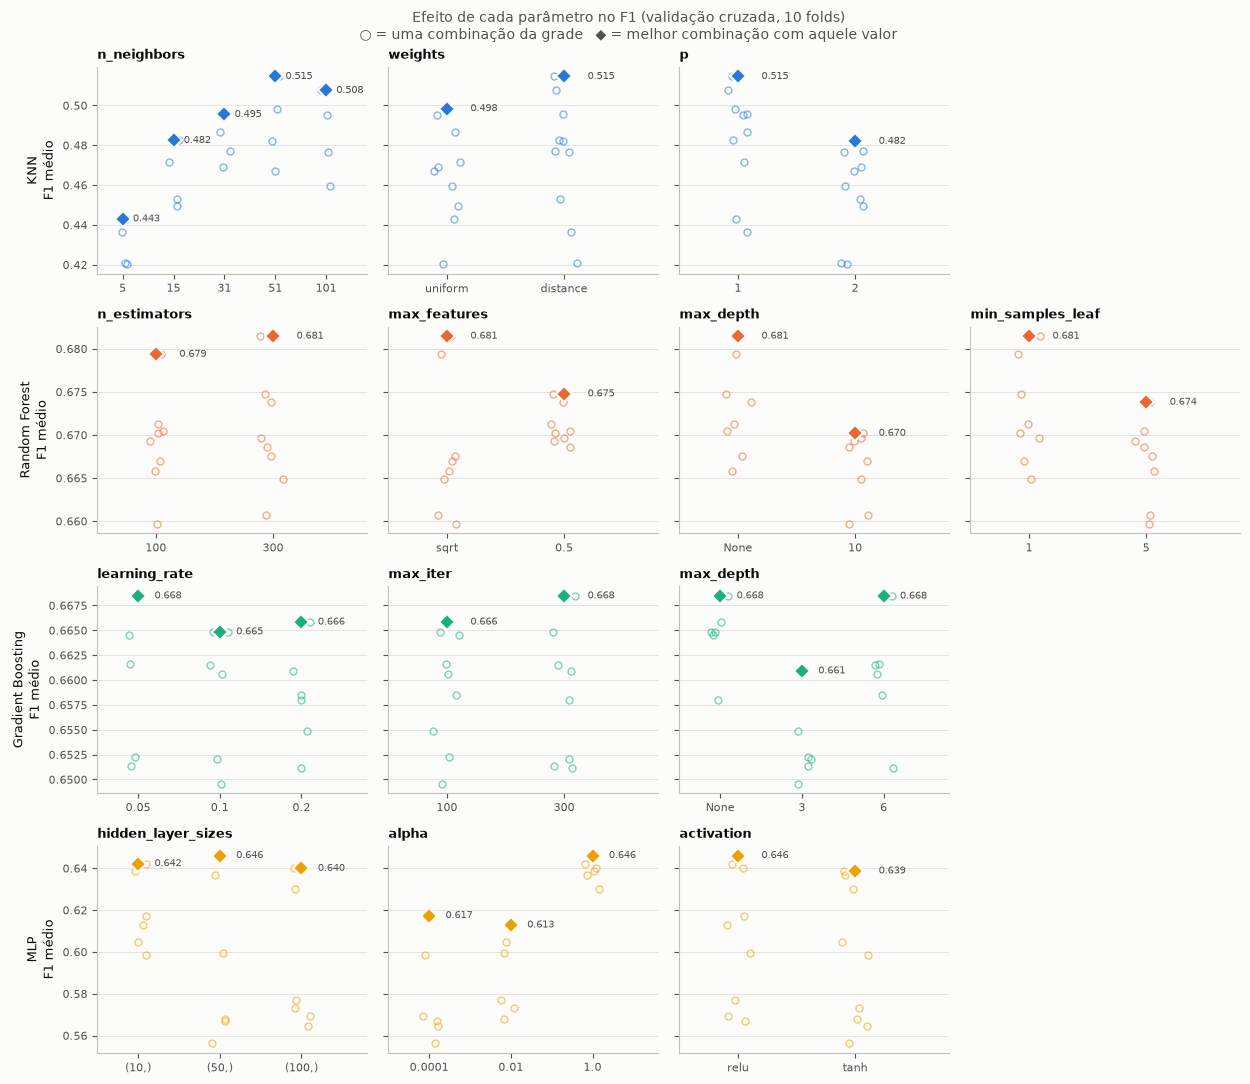

In [11]:
max_parametros = max(len(grade) for _, grade in GRADES.values())
fig, eixos = plt.subplots(len(GRADES), max_parametros, figsize=(12.5, 11), sharey="row")
gerador = np.random.default_rng(SEMENTE)
for linha, (algoritmo, (_, grade)) in enumerate(GRADES.items()):
    cor = COR_ALGORITMO[algoritmo]
    f1_algoritmo = media.loc[algoritmo, "f1"]
    for coluna in range(max_parametros):
        ax = eixos[linha, coluna]
        if coluna >= len(grade):
            ax.set_visible(False)
            continue
        parametro, valores = list(grade.items())[coluna]
        for x, valor in enumerate(valores):
            f1s = np.array([f1_algoritmo[cfg] for (alg, cfg), p in PARAMS.items()
                            if alg == algoritmo and p[parametro] == valor])
            ax.plot(x + gerador.uniform(-0.12, 0.12, len(f1s)), f1s, "o", markersize=5,
                    markerfacecolor="none", markeredgecolor=cor, alpha=0.55, linestyle="")
            ax.plot(x, f1s.max(), "D", markersize=8, color=cor, markeredgecolor=COR["fundo"], markeredgewidth=1.5)
            ax.text(x + 0.2, f1s.max(), f"{f1s.max():.3f}", va="center", fontsize=7, color=COR["texto2"])
        ax.set_xticks(range(len(valores)), [str(v) for v in valores])
        ax.set_xlim(-0.5, len(valores) - 0.2)
        ax.set_title(parametro, loc="left", fontsize=9)
        ax.grid(axis="x", visible=False)
    eixos[linha, 0].set_ylabel(f"{algoritmo}\nF1 médio", fontsize=9, color=COR["texto"])
fig.suptitle("Efeito de cada parâmetro no F1 (validação cruzada, 10 folds)\n"
             "○ = uma combinação da grade   ◆ = melhor combinação com aquele valor",
             fontsize=10, color=COR["texto2"])
fig.tight_layout()
salvar_figura(fig, "01_efeito_dos_parametros")

### 6.2 Os parâmetros mudam o resultado?

A amplitude é a diferença de F1 entre a melhor e a pior combinação de cada algoritmo. Quando ela é maior que o
desvio padrão entre os folds, a escolha dos parâmetros muda o resultado de fato. Quando é menor, as diferenças se
confundem com a variação causada pelos dados.

In [12]:
sensibilidade = modelos_cv.groupby(level="algoritmo", sort=False)["f1"].agg(
    combinacoes="size", f1_pior="min", f1_melhor="max")
sensibilidade["amplitude"] = sensibilidade["f1_melhor"] - sensibilidade["f1_pior"]
sensibilidade["dp_medio_entre_folds"] = desvio.drop(index="Linha de base").groupby(
    level="algoritmo", sort=False)["f1"].mean()
salvar_tabela(sensibilidade, "06_sensibilidade_aos_parametros")
sensibilidade

,combinacoes,f1_pior,f1_melhor,amplitude,dp_medio_entre_folds
algoritmo,,,,,
KNN,20,0.4203,0.5145,0.0942,0.0212
Random Forest,16,0.6597,0.6815,0.0218,0.0296
Gradient Boosting,18,0.6496,0.6685,0.0189,0.0318
MLP,18,0.5563,0.6461,0.0898,0.0317


### 6.3 As cinco melhores combinações de cada algoritmo

Ordenadas pelo F1 médio, a métrica de escolha:

In [13]:
top5 = pd.concat([modelos_cv.loc[[alg]].nlargest(5, "f1") for alg in GRADES])
salvar_tabela(top5[["f1", "pr_auc", "precisao", "revocacao"]].join(desvio[["f1", "pr_auc"]].add_suffix("_dp")),
              "07_cinco_melhores_por_algoritmo")
media_mais_desvio(top5.index, ["f1", "pr_auc", "precisao", "revocacao"])

F1  \
algoritmo         configuracao                                                        
KNN               n_neighbors=51, weights=distance, p=1               0.515 ± 0.018   
                  n_neighbors=101, weights=distance, p=1              0.508 ± 0.022   
                  n_neighbors=51, weights=uniform, p=1                0.498 ± 0.017   
                  n_neighbors=31, weights=distance, p=1               0.495 ± 0.017   
                  n_neighbors=101, weights=uniform, p=1               0.495 ± 0.027   
Random Forest     n_estimators=300, max_features=sqrt, max_depth=...  0.681 ± 0.036   
                  n_estimators=100, max_features=sqrt, max_depth=...  0.679 ± 0.032   
                  n_estimators=300, max_features=0.5, max_depth=N...  0.675 ± 0.034   
                  n_estimators=300, max_features=0.5, max_depth=N...  0.674 ± 0.031   
                  n_estimators=100, max_features=0.5, max_depth=N...  0.671 ± 0.035   
Gradient Boosting learning_rate=0.05, max_iter=300, max_depth=None    0.668 ± 0.034   
                  learning_rate=0.05, max_iter=300, max_depth=6       0.668 ± 0.038   
                  learning_rate=0.2, max_iter=100, max_depth=None     0.666 ± 0.034   
                  learning_rate=0.1, max_iter=100, max_depth=None     0.665 ± 0.033   
                  learning_rate=0.1, max_iter=300, max_depth=None     0.665 ± 0.038   
MLP               hidden_layer_sizes=(50,), alpha=1.0, activation...  0.646 ± 0.031   
                  hidden_layer_sizes=(10,), alpha=1.0, activation...  0.642 ± 0.032   
                  hidden_layer_sizes=(100,), alpha=1.0, activatio...  0.640 ± 0.030   
                  hidden_layer_sizes=(10,), alpha=1.0, activation...  0.639 ± 0.032   
                  hidden_layer_sizes=(50,), alpha=1.0, activation...  0.637 ± 0.032   

                                                                             PR-AUC  \
algoritmo         configuracao                                                        
KNN               n_neighbors=51, weights=distance, p=1               0.514 ± 0.030   
                  n_neighbors=101, weights=distance, p=1              0.526 ± 0.030   
                  n_neighbors=51, weights=uniform, p=1                0.497 ± 0.032   
                  n_neighbors=31, weights=distance, p=1               0.498 ± 0.029   
                  n_neighbors=101, weights=uniform, p=1               0.505 ± 0.035   
Random Forest     n_estimators=300, max_features=sqrt, max_depth=...  0.738 ± 0.032   
                  n_estimators=100, max_features=sqrt, max_depth=...  0.732 ± 0.034   
                  n_estimators=300, max_features=0.5, max_depth=N...  0.730 ± 0.034   
                  n_estimators=300, max_features=0.5, max_depth=N...  0.747 ± 0.031   
                  n_estimators=100, max_features=0.5, max_depth=N...  0.726 ± 0.037   
Gradient Boosting learning_rate=0.05, max_iter=300, max_depth=None    0.739 ± 0.034   
                  learning_rate=0.05, max_iter=300, max_depth=6       0.738 ± 0.040   
                  learning_rate=0.2, max_iter=100, max_depth=None     0.728 ± 0.035   
                  learning_rate=0.1, max_iter=100, max_depth=None     0.740 ± 0.034   
                  learning_rate=0.1, max_iter=300, max_depth=None     0.727 ± 0.036   
MLP               hidden_layer_sizes=(50,), alpha=1.0, activation...  0.700 ± 0.037   
                  hidden_layer_sizes=(10,), alpha=1.0, activation...  0.695 ± 0.037   
                  hidden_layer_sizes=(100,), alpha=1.0, activatio...  0.701 ± 0.037   
                  hidden_layer_sizes=(10,), alpha=1.0, activation...  0.693 ± 0.039   
                  hidden_layer_sizes=(50,), alpha=1.0, activation...  0.694 ± 0.038   

                                                                           Precisão  \
algoritmo         configuracao                                                        
KNN               n_neighbors=51, weights=distance, p=1               0.392 ±

### 6.4 Melhor parametrização de cada algoritmo

A escolhida é a combinação de **maior F1 médio** na validação cruzada:

In [14]:
melhores = modelos_cv.groupby(level="algoritmo", sort=False)["f1"].idxmax().map(lambda t: t[1])
melhores.name = "melhor_configuracao"
indices_melhores = list(melhores.items())
tabela_melhores = media.loc[indices_melhores, ["f1", "pr_auc", "precisao", "revocacao"]].join(
    desvio[["f1", "pr_auc"]].add_suffix("_dp"))
salvar_tabela(tabela_melhores, "08_melhores_parametrizacoes")
media_mais_desvio(indices_melhores, ["f1", "pr_auc", "precisao", "revocacao"])

,F1,PR-AUC,Precisão,Revocação
"(KNN, n_neighbors=51, weights=distance, p=1)",0.515 ± 0.018,0.514 ± 0.030,0.392 ± 0.016,0.749 ± 0.031
"(Random Forest, n_estimators=300, max_features=sqrt, max_depth=None, min_samples_leaf=1)",0.681 ± 0.036,0.738 ± 0.032,0.634 ± 0.037,0.737 ± 0.043
"(Gradient Boosting, learning_rate=0.05, max_iter=300, max_depth=None)",0.668 ± 0.034,0.739 ± 0.034,0.602 ± 0.031,0.753 ± 0.045
"(MLP, hidden_layer_sizes=(50,), alpha=1.0, activation=relu)",0.646 ± 0.031,0.700 ± 0.037,0.541 ± 0.032,0.804 ± 0.040


## 7. Avaliação final no conjunto de teste

A melhor parametrização de cada algoritmo é treinada com **todo o conjunto de treino** (80%) e avaliada **uma única
vez** no teste (20%), que não participou de nenhuma escolha até aqui.

In [15]:
modelos_finais, previsoes, probabilidades = {}, {}, {}
for algoritmo, configuracao in melhores.items():
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always", ConvergenceWarning)
        modelo = montar_pipeline(algoritmo, PARAMS[(algoritmo, configuracao)]).fit(X_treino, y_treino)
    convergiu = not any(issubclass(a.category, ConvergenceWarning) for a in avisos)
    modelos_finais[algoritmo] = modelo
    previsoes[algoritmo] = modelo.predict(X_teste)
    probabilidades[algoritmo] = modelo.predict_proba(X_teste)[:, 1]
    extra = f" | iterações: {modelo.named_steps['modelo'].n_iter_}, convergiu: {convergiu}" if algoritmo == "MLP" else ""
    print(f"{algoritmo:<18} treinado com {configuracao}{extra}")

KNN                treinado com n_neighbors=51, weights=distance, p=1


Random Forest      treinado com n_estimators=300, max_features=sqrt, max_depth=None, min_samples_leaf=1


Gradient Boosting  treinado com learning_rate=0.05, max_iter=300, max_depth=None


MLP                treinado com hidden_layer_sizes=(50,), alpha=1.0, activation=relu | iterações: 93, convergiu: True


In [16]:
FUNCOES = {
    "acuracia": lambda yv, yp, pr: accuracy_score(yv, yp),
    "acuracia_balanceada": lambda yv, yp, pr: balanced_accuracy_score(yv, yp),
    "precisao": lambda yv, yp, pr: precision_score(yv, yp, zero_division=0),
    "revocacao": lambda yv, yp, pr: recall_score(yv, yp),
    "f1": lambda yv, yp, pr: f1_score(yv, yp),
    "roc_auc": lambda yv, yp, pr: roc_auc_score(yv, pr),
    "pr_auc": lambda yv, yp, pr: average_precision_score(yv, pr),
    "mcc": lambda yv, yp, pr: matthews_corrcoef(yv, yp),
}
resultados_teste = pd.DataFrame({
    algoritmo: {m: f(y_teste, previsoes[algoritmo], probabilidades[algoritmo]) for m, f in FUNCOES.items()}
    for algoritmo in melhores.index
}).T
resultados_teste.index.name = "algoritmo"
resultados_teste.insert(0, "configuracao", melhores)

# Tabela comparativa: métricas escolhidas primeiro, ordenada pelo F1
ORDEM_COLUNAS = ["configuracao", "f1", "pr_auc", "precisao", "revocacao",
                 "acuracia", "acuracia_balanceada", "roc_auc", "mcc"]
tabela_comparativa = resultados_teste[ORDEM_COLUNAS].sort_values("f1", ascending=False)
tabela_comparativa.insert(1, "f1_validacao_cruzada", tabela_melhores["f1"].droplevel("configuracao"))
salvar_tabela(tabela_comparativa, "09_comparacao_final_teste")
tabela_comparativa.rename(columns=NOME_METRICA | {"configuracao": "Parametrização",
                                                  "f1_validacao_cruzada": "F1 (val. cruzada)"})

,Parametrização,F1 (val. cruzada),F1,PR-AUC,Precisão,Revocação,Acurácia,Acurácia balanceada,ROC-AUC,MCC
algoritmo,,,,,,,,,,
Random Forest,"n_estimators=300, max_features=sqrt, max_depth...",0.6815,0.6828,0.7388,0.6331,0.7408,0.8923,0.8306,0.9284,0.6211
Gradient Boosting,"learning_rate=0.05, max_iter=300, max_depth=None",0.6685,0.6659,0.7271,0.5884,0.7670,0.8796,0.8337,0.9274,0.6018
MLP,"hidden_layer_sizes=(50,), alpha=1.0, activatio...",0.6461,0.6554,0.7098,0.5485,0.8141,0.8660,0.8449,0.9257,0.5935
KNN,"n_neighbors=51, weights=distance, p=1",0.5145,0.5347,0.5551,0.4026,0.7958,0.7833,0.7884,0.8608,0.4534


A coluna **F1 (val. cruzada)** repete o resultado médio da validação cruzada para comparação. Se o F1 no teste
ficar próximo dele (dentro de cerca de um desvio padrão), a estimativa da validação cruzada era confiável e não houve
sobreajuste na escolha dos hiperparâmetros.

### 7.1 Matrizes de confusão

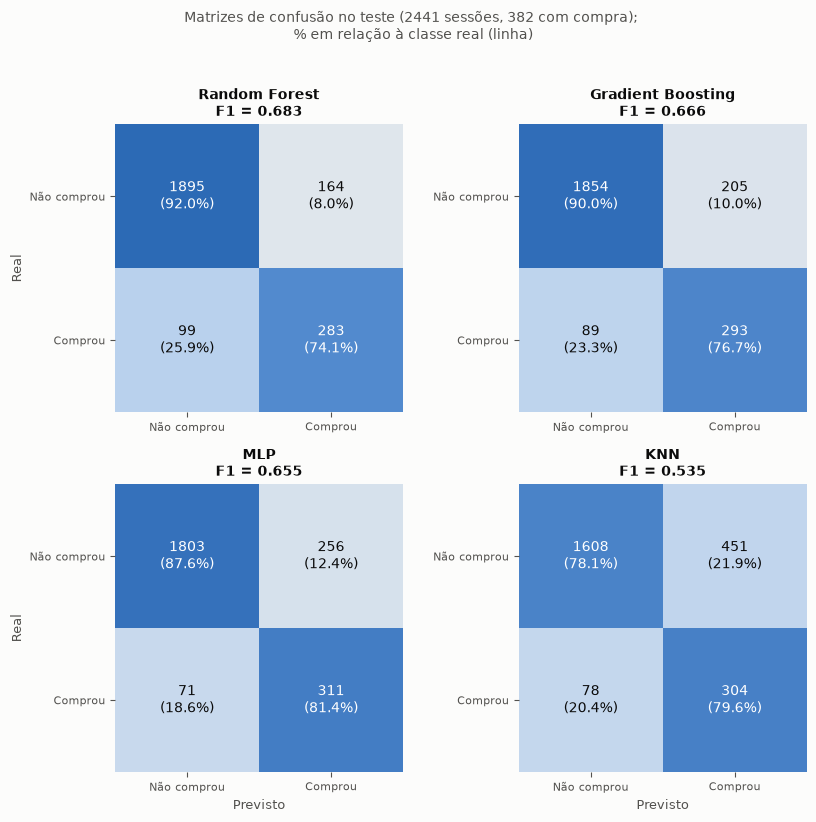

,verdadeiro_negativo,falso_positivo,falso_negativo,verdadeiro_positivo
algoritmo,,,,
Random Forest,1895,164,99,283
Gradient Boosting,1854,205,89,293
MLP,1803,256,71,311
KNN,1608,451,78,304


In [17]:
CLASSES = ["Não comprou", "Comprou"]
ordem = list(tabela_comparativa.index)
fig, eixos = plt.subplots(2, 2, figsize=(8.5, 8))
linhas_matrizes = []
for k, (ax, algoritmo) in enumerate(zip(eixos.flat, ordem)):
    matriz = confusion_matrix(y_teste, previsoes[algoritmo])
    pct_linha = matriz / matriz.sum(axis=1, keepdims=True)
    ax.imshow(pct_linha, cmap=MAPA_SEQUENCIAL, vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{matriz[i, j]}\n({100 * pct_linha[i, j]:.1f}%)", ha="center", va="center",
                    fontsize=10, color="white" if pct_linha[i, j] > 0.6 else COR["texto"])
    ax.set_xticks([0, 1], CLASSES)
    ax.set_yticks([0, 1], CLASSES)
    ax.set_xlabel("Previsto" if k >= 2 else "")
    ax.set_ylabel("Real" if k % 2 == 0 else "")
    ax.grid(False)
    for lado in ax.spines.values():
        lado.set_visible(False)
    ax.set_title(f"{algoritmo}\nF1 = {f1_score(y_teste, previsoes[algoritmo]):.3f}", fontsize=10)
    (vn, fp), (fn, vp) = matriz
    linhas_matrizes.append({"algoritmo": algoritmo, "verdadeiro_negativo": vn, "falso_positivo": fp,
                            "falso_negativo": fn, "verdadeiro_positivo": vp})
fig.suptitle(f"Matrizes de confusão no teste ({len(y_teste)} sessões, {int(y_teste.sum())} com compra); "
             "\n% em relação à classe real (linha)", y=1.02, fontsize=10, color=COR["texto2"])
fig.tight_layout()
salvar_figura(fig, "02_matrizes_confusao_teste")

matrizes = pd.DataFrame(linhas_matrizes).set_index("algoritmo")
salvar_tabela(matrizes, "10_matrizes_confusao_teste")
matrizes

Leitura das matrizes: na linha **Comprou**, a célula da direita são os compradores encontrados (verdadeiros
positivos) e a da esquerda os compradores perdidos (falsos negativos). Na linha **Não comprou**, a célula da direita
são os alarmes falsos (falsos positivos).

### 7.2 Curvas de precisão × revocação

A curva mostra a precisão e a revocação de cada algoritmo para todos os limiares de decisão. A área sob ela é a
PR-AUC. O ponto marca o limiar padrão de 0,5, que gera as matrizes de confusão acima.

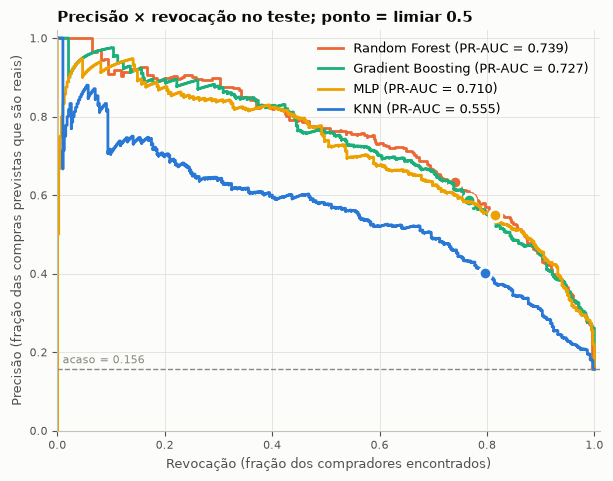

In [18]:
fig, ax = plt.subplots(figsize=(7, 5.2))
for algoritmo in ordem:
    precisao, revocacao, _ = precision_recall_curve(y_teste, probabilidades[algoritmo])
    ap = average_precision_score(y_teste, probabilidades[algoritmo])
    cor = COR_ALGORITMO[algoritmo]
    ax.plot(revocacao, precisao, color=cor, linewidth=2, drawstyle="steps-post",
            label=f"{algoritmo} (PR-AUC = {ap:.3f})")
    ax.plot(recall_score(y_teste, previsoes[algoritmo]), precision_score(y_teste, previsoes[algoritmo]),
            marker="o", markersize=9, color=cor, markeredgecolor=COR["fundo"], markeredgewidth=2)
prevalencia_teste = y_teste.mean()
ax.axhline(prevalencia_teste, color=COR["mudo"], linestyle="--", linewidth=1)
ax.text(0.01, prevalencia_teste + 0.015, f"acaso = {prevalencia_teste:.3f}", fontsize=8, color=COR["mudo"])
ax.set_xlim(0, 1.01)
ax.set_ylim(0, 1.02)
ax.set_xlabel("Revocação (fração dos compradores encontrados)")
ax.set_ylabel("Precisão (fração das compras previstas que são reais)")
ax.set_title("Precisão × revocação no teste; ponto = limiar 0.5", loc="left")
ax.legend(loc="upper right")
salvar_figura(fig, "03_curvas_precisao_revocacao_teste")

### 7.3 Comparação das métricas escolhidas

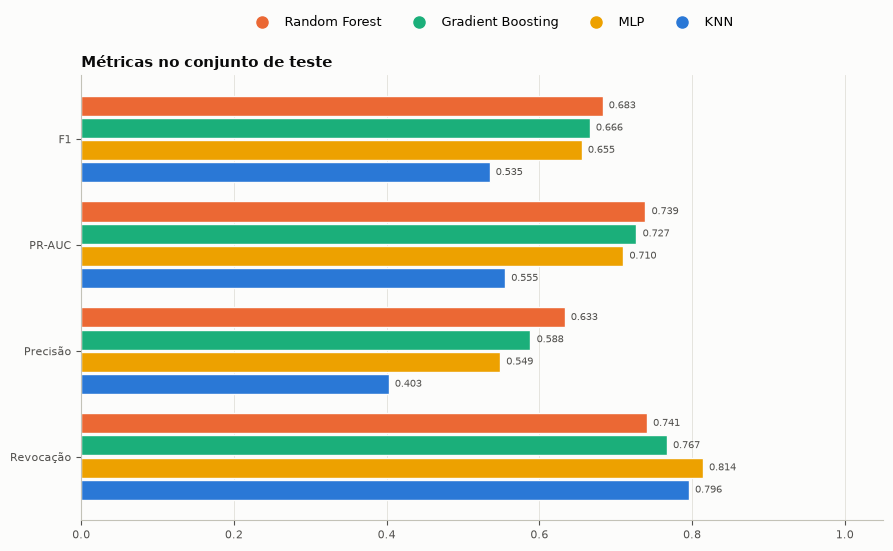

In [19]:
METRICAS_GRAFICO = ["f1", "pr_auc", "precisao", "revocacao"]
fig, ax = plt.subplots(figsize=(9, 5.4))
altura = 0.19
for i, metrica in enumerate(METRICAS_GRAFICO):
    for j, algoritmo in enumerate(ordem):
        valor = resultados_teste.loc[algoritmo, metrica]
        pos = i + (j - 1.5) * (altura + 0.02)
        ax.barh(pos, valor, height=altura, color=COR_ALGORITMO[algoritmo],
                edgecolor=COR["fundo"], linewidth=1)
        ax.text(valor + 0.008, pos, f"{valor:.3f}", va="center", fontsize=7.5, color=COR["texto2"])
ax.set_yticks(range(len(METRICAS_GRAFICO)), [NOME_METRICA[m] for m in METRICAS_GRAFICO])
ax.invert_yaxis()
ax.set_xlim(0, 1.05)
ax.grid(axis="y", visible=False)
ax.set_title("Métricas no conjunto de teste", loc="left")
legenda_algoritmos(fig, algoritmos={a: COR_ALGORITMO[a] for a in ordem}, bbox_to_anchor=(0.55, 1.02))
fig.tight_layout(rect=(0, 0, 1, 0.95))
salvar_figura(fig, "04_comparacao_metricas_teste")

## 8. Conclusões

**Métricas.** Com 84% de sessões sem compra, a acurácia é enganosa: atinge 84,4% sem encontrar nenhum comprador e,
na busca em grade, escolheria as combinações que encontram menos compradores. As métricas escolhidas são o
**F1 da classe "comprou"**, que é a principal e decide as parametrizações, e a **PR-AUC**, como segunda métrica.
Precisão, revocação e matriz de confusão as complementam.

**Parametrizações (busca em grade, 72 combinações).**
- **KNN e MLP são sensíveis aos parâmetros.** A diferença entre a melhor e a pior combinação (0,094 e 0,090 de F1)
  é cerca de três vezes o desvio padrão entre os folds.
  - **MLP:** a regularização é decisiva. Todas as combinações com `alpha=1` ficam entre 0,630 e 0,646 de F1, e as
    redes de 50 e 100 neurônios com `alpha` pequeno caem para 0,556–0,599, porque decoram o treino. O tamanho da
    camada e a função de ativação pesam pouco quando a regularização é forte.
  - **KNN:** melhora com mais vizinhos até k=51 (de 0,443 com k=5 para 0,515). A distância de Manhattan (`p=1`)
    supera a euclidiana em todos os valores de k, e o peso por distância ajuda um pouco.
- **Random Forest e Gradient Boosting são pouco sensíveis.** As 16 e 18 combinações ficam dentro de uma faixa de
  0,022 e 0,019 de F1, menor que o desvio padrão entre os folds (~0,03). Os valores padrão já funcionam bem.

**Resultado no teste.** O F1 de cada algoritmo no teste ficou a no máximo 0,02 do F1 médio da validação cruzada,
confirmando que a escolha dos hiperparâmetros não foi sobreajustada.

| Posição | Algoritmo | Melhor parametrização | F1 | PR-AUC | Leitura |
|---|---|---|---|---|---|
| 1 | Random Forest | 300 árvores, `max_features=sqrt`, sem limite de profundidade, folha ≥ 1 | 0,683 | 0,739 | Melhor nas duas métricas e o mais preciso: 164 alarmes falsos para 283 compradores encontrados. |
| 2 | Gradient Boosting | `learning_rate=0.05`, 300 árvores, sem limite de profundidade | 0,666 | 0,727 | Praticamente empatado com o Random Forest: a diferença de F1 (0,017) é menor que o desvio padrão entre os folds. |
| 3 | MLP | 50 neurônios, `alpha=1`, relu | 0,655 | 0,710 | Maior revocação (81,4% dos compradores encontrados), à custa de mais alarmes falsos (256). |
| 4 | KNN | k=51, peso por distância, Manhattan | 0,535 | 0,555 | Bem atrás: 451 alarmes falsos para 304 compradores encontrados. |

**Por que o KNN ficou atrás.** A causa provável é o pré-processamento, e não o algoritmo. Das 55 colunas que
entram no cálculo da distância, 47 vêm do one-hot dos atributos categóricos. Duas sessões que diferem só no
navegador ou no tipo de tráfego ficam tão distantes quanto duas com `PageValues` muito diferente, embora
`PageValues` seja o atributo mais relacionado à compra (correlação de 0,63 na análise exploratória). A vantagem da
distância de Manhattan reforça essa explicação. Na euclidiana, as diferenças dos atributos numéricos (entre 0 e 1)
são elevadas ao quadrado e encolhem, enquanto as do one-hot (0 ou 1) não mudam. A Manhattan não encolhe as
diferenças numéricas e, por isso, dá a elas um pouco mais de peso.

**Escolha do modelo.** O **Random Forest** é o melhor modelo pelo critério adotado (F1), seguido de perto pelo
Gradient Boosting. Se perder um comprador custasse muito mais que um alarme falso, o MLP seria preferível pela
revocação maior. As curvas de precisão × revocação mostram, porém, que Random Forest e Gradient Boosting atingem a
mesma revocação baixando o limiar de decisão, com precisão semelhante.